# Clustering Quality Evaluation: Spark Parallel K-Means vs. Traditional K-Means

This notebook presents the independently verified clustering-quality results
(purity, Adjusted Rand Index, Normalized Mutual Information) for the
labeled-sample evaluation path of this project.

**Scope.** This covers the *labeled sample* comparisons only (synthetic-1K and
a 1,000-record KDD99 sample), using ground-truth class labels held out of
clustering and applied only afterward for evaluation. It does **not** cover
the historical 10K/50K synthetic scalability study (see
`results/figures/stage-9h2-runtime-comparison.png` and
`stage-9h4-speedup-comparison.png` for that separate study, and the README's
Section 12 for its runtime/SSE results).

Source data: `results/verified_quality/clustering_quality_comparison.csv`
(independently verified; see `src/experiments/clustering_quality.py` for the
purity/ARI/NMI computation and `src/experiments/clustering_quality_report.py`
for the loader/summary code used below).

In [1]:
import sys
from pathlib import Path

def find_repo_root(marker: str = "README.md") -> Path:
    """Walk upward from the notebook's directory until marker is found.

    Works regardless of which directory the notebook is launched from
    (repo root, notebooks/, or elsewhere), as long as it stays inside
    the repository.
    """
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(
        f"Could not locate repo root (looked for {marker!r} above {here})."
    )

REPO_ROOT = find_repo_root()
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np

from src.experiments.clustering_quality_report import (
    load_quality_comparison_csv,
    summarize_quality_comparisons,
)

CSV_PATH = REPO_ROOT / "results" / "verified_quality" / "clustering_quality_comparison.csv"
FIGURES_DIR = REPO_ROOT / "results" / "figures"

rows = load_quality_comparison_csv(CSV_PATH)
summaries = summarize_quality_comparisons(rows)

print(f"Loaded {len(rows)} verified measurement rows.")
print(f"Built {len(summaries)} dataset-level comparisons: "
      f"{[s.dataset_name for s in summaries]}")

Loaded 6 verified measurement rows.
Built 2 dataset-level comparisons: ['kdd99', 'synthetic']


## Raw verified measurements

In [2]:
print(f"{'dataset':<10} {'algorithm':<18} {'master':<16} {'sse':>12} "
      f"{'purity':>8} {'ari':>8} {'nmi':>8} {'time(s)':>9}")
print("-" * 95)
for r in rows:
    print(f"{r.dataset_name:<10} {r.algorithm:<18} {r.master:<16} "
          f"{r.sse:>12.2f} {r.purity:>8.4f} {r.adjusted_rand_index:>8.4f} "
          f"{r.normalized_mutual_information:>8.4f} {r.elapsed_seconds:>9.4f}")

dataset    algorithm          master                    sse   purity      ari      nmi   time(s)
-----------------------------------------------------------------------------------------------
synthetic  parallel_kmeans    local[1]              1032.37   1.0000   1.0000   1.0000    1.6056
synthetic  parallel_kmeans    local[2]              1032.37   1.0000   1.0000   1.0000    0.9979
kdd99      parallel_kmeans    local[1]             21072.55   0.7970  -0.0054   0.0111    1.2167
kdd99      parallel_kmeans    local[2]             21072.55   0.7970  -0.0054   0.0111    1.0420
synthetic  traditional_kmeans single_process        1032.37   1.0000   1.0000   1.0000    0.4779
kdd99      traditional_kmeans single_process        9342.83   0.9750   0.4318   0.5352    0.6014


## Per-dataset summary: Spark vs. traditional K-Means

In [3]:
for s in summaries:
    print(f"=== {s.dataset_name} ===")
    print(f"  Spark {s.spark_base_master}:  {s.spark_base_seconds:.4f}s")
    if s.speedup:
        print(f"  Spark {s.spark_comparison_master}:  "
              f"{s.spark_comparison_master_seconds:.4f}s  "
              f"(speedup {s.speedup:.2f}x vs {s.spark_base_master})")
    print(f"  Traditional:    {s.traditional_seconds:.4f}s")
    print()
    print(f"  {'metric':<8} {'spark':>10} {'traditional':>12} {'gap':>10}")
    print(f"  {'purity':<8} {s.spark_purity:>10.4f} "
          f"{s.traditional_purity:>12.4f} {s.purity_gap:>10.4f}")
    print(f"  {'ari':<8} {s.spark_adjusted_rand_index:>10.4f} "
          f"{s.traditional_adjusted_rand_index:>12.4f} "
          f"{s.adjusted_rand_index_gap:>10.4f}")
    print(f"  {'nmi':<8} {s.spark_normalized_mutual_information:>10.4f} "
          f"{s.traditional_normalized_mutual_information:>12.4f} "
          f"{s.normalized_mutual_information_gap:>10.4f}")
    print()

=== kdd99 ===
  Spark local[1]:  1.2167s
  Spark local[2]:  1.0420s  (speedup 1.17x vs local[1])
  Traditional:    0.6014s

  metric        spark  traditional        gap
  purity       0.7970       0.9750    -0.1780
  ari         -0.0054       0.4318    -0.4372
  nmi          0.0111       0.5352    -0.5241

=== synthetic ===
  Spark local[1]:  1.6056s
  Spark local[2]:  0.9979s  (speedup 1.61x vs local[1])
  Traditional:    0.4779s

  metric        spark  traditional        gap
  purity       1.0000       1.0000     0.0000
  ari          1.0000       1.0000     0.0000
  nmi          1.0000       1.0000     0.0000



## Chart: clustering quality (purity / ARI / NMI), Spark vs. traditional

Grouped bars per dataset. Purity ranges 0-1 and can look deceptively good on
imbalanced data; ARI and NMI are shown alongside it for exactly that reason
(ARI is corrected for chance and can go negative).

Saved: /home/claude/opaksbolu/csce5300-big-data-project/results/figures/stage-quality-comparison-purity-ari-nmi.png


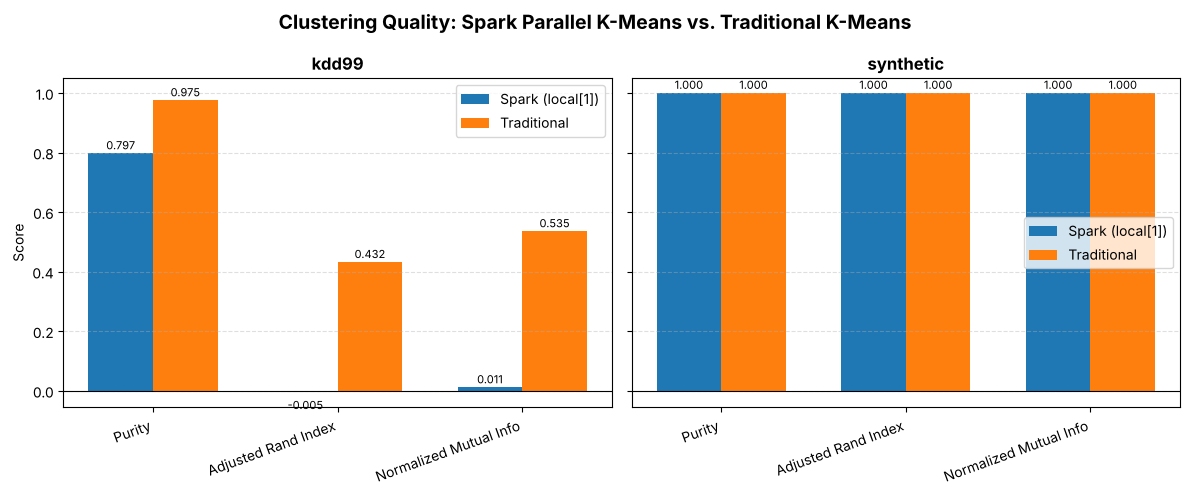

In [4]:
metrics = ["purity", "ari", "nmi"]
metric_labels = ["Purity", "Adjusted Rand Index", "Normalized Mutual Info"]

fig, axes = plt.subplots(1, len(summaries), figsize=(6 * len(summaries), 5),
                          sharey=True)
if len(summaries) == 1:
    axes = [axes]

for ax, s in zip(axes, summaries):
    spark_values = [
        s.spark_purity,
        s.spark_adjusted_rand_index,
        s.spark_normalized_mutual_information,
    ]
    traditional_values = [
        s.traditional_purity,
        s.traditional_adjusted_rand_index,
        s.traditional_normalized_mutual_information,
    ]

    x = np.arange(len(metrics))
    width = 0.35

    bars_spark = ax.bar(x - width / 2, spark_values, width,
                         label=f"Spark ({s.spark_base_master})",
                         color="#1f77b4")
    bars_trad = ax.bar(x + width / 2, traditional_values, width,
                        label="Traditional", color="#ff7f0e")

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(s.dataset_name, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(metric_labels, rotation=20, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend()

    for bars in (bars_spark, bars_trad):
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f"{height:.3f}",
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3 if height >= 0 else -12),
                        textcoords="offset points",
                        ha="center", fontsize=8)

axes[0].set_ylabel("Score")
fig.suptitle("Clustering Quality: Spark Parallel K-Means vs. Traditional K-Means",
             fontsize=14, fontweight="bold")
fig.tight_layout()

output_path = FIGURES_DIR / "stage-quality-comparison-purity-ari-nmi.png"
fig.savefig(output_path, dpi=150, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

## Interpretation

- **Synthetic-1K:** Spark and traditional K-Means are essentially identical
  and perfect (purity = ARI = NMI = 1.0). This is expected: the synthetic
  clusters are well-separated by construction, so both algorithms recover
  the true structure regardless of initialization differences.

- **KDD99 sample:** Purity alone looks reasonable for Spark (0.797), but ARI
  is **negative** (-0.005) and NMI is near zero (0.011) — meaning, relative
  to chance, Spark's clustering captured almost no correspondence with the
  true intrusion-type labels. Traditional K-Means on the same 1,000-record
  sample did meaningfully better (ARI 0.432, NMI 0.535).

- **Why purity is misleading here:** KDD99's classes are heavily imbalanced
  (one class dominates the sample). A clustering can score high purity by
  grouping most points into one dominant cluster without separating the
  minority classes at all — which is consistent with the recorded
  `cluster_counts` for the KDD99/Spark row (`1;936;1;61;1`): one cluster
  absorbs 936 of 1,000 records. This is exactly why ARI/NMI are reported
  alongside purity rather than purity alone.

- **Caveat (carried from the project README):** the traditional and parallel
  implementations use different initialization procedures, so this quality
  gap should not be read as a clean apples-to-apples algorithm comparison —
  it may partly reflect initialization sensitivity rather than a pure
  Spark-vs-traditional effect. Confirming that would require rerunning with
  matched initializations, which is out of scope for this evaluation.

## Chart: measured runtime, Spark vs. traditional

For context alongside quality. This mirrors the "Controlled sample
observations" table in the README's Final Integration Status section.

Saved: /home/claude/opaksbolu/csce5300-big-data-project/results/figures/stage-quality-comparison-runtime.png


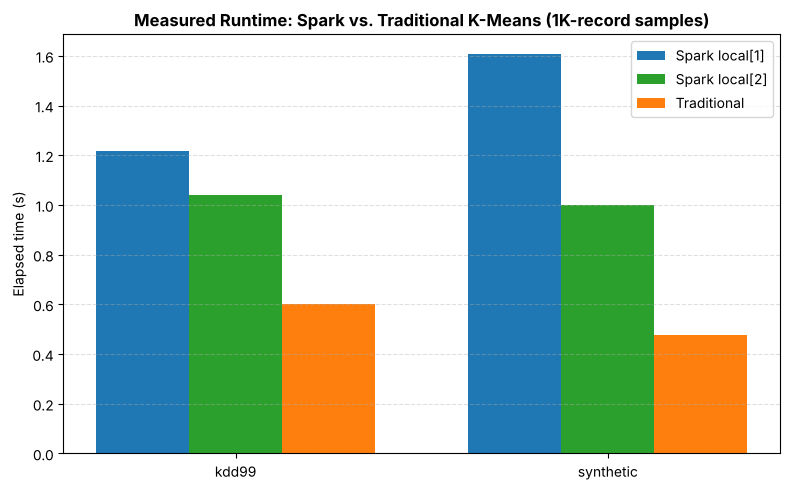

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

labels = [s.dataset_name for s in summaries]
x = np.arange(len(labels))
width = 0.25

base_times = [s.spark_base_seconds for s in summaries]
comparison_times = [
    s.spark_comparison_master_seconds
    if s.spark_comparison_master_seconds is not None else 0
    for s in summaries
]
traditional_times = [s.traditional_seconds for s in summaries]

ax.bar(x - width, base_times, width,
       label=f"Spark {summaries[0].spark_base_master}", color="#1f77b4")
ax.bar(x, comparison_times, width,
       label=f"Spark {summaries[0].spark_comparison_master or 'n/a'}",
       color="#2ca02c")
ax.bar(x + width, traditional_times, width,
       label="Traditional", color="#ff7f0e")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Elapsed time (s)")
ax.set_title("Measured Runtime: Spark vs. Traditional K-Means (1K-record samples)",
             fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()
fig.tight_layout()

output_path = FIGURES_DIR / "stage-quality-comparison-runtime.png"
fig.savefig(output_path, dpi=150, bbox_inches="tight")
print(f"Saved: {output_path}")
plt.show()

## Summary for the report / presentation

| Dataset | Spark purity | Spark ARI | Spark NMI | Traditional purity | Traditional ARI | Traditional NMI |
|---|---:|---:|---:|---:|---:|---:|
| kdd99 | 0.797 | -0.005 | 0.011 | 0.975 | 0.432 | 0.535 |
| synthetic | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 | 1.000 |

**Headline finding:** parallel and traditional K-Means are indistinguishable
on well-separated synthetic data, but on real, imbalanced KDD99 data the
Spark run's clustering quality is substantially worse than the traditional
baseline on every metric except raw purity, and purity itself is shown here
to be a misleading metric on this dataset — ARI and NMI reveal the gap that
purity hides.